# B2. PURPLE 은 purity 와 ploidy 를 어떻게 맞추나

**목표**
- PURPLE 의 맞추기(fitting) 과정을 처음부터 끝까지 그림으로 따라가고 직접 돌려 봅니다.
- deviation 벌점과 event 벌점이 각각 무엇을 막으려는 것인지 이해합니다.
- 같은 데이터를 똑같이 잘 설명하는 다른 해(解)가 있다는 것을 그림과 식으로 확인합니다.

**이 노트북이 답하는 질문**: 같은 데이터를 설명하는 (purity, ploidy) 조합이 여러 개일 때 PURPLE 은 무엇으로 하나를 고르나?

식은 PURPLE 4.1 소스(태그 `purple-v4.1`)에서 옮긴 `purple_mini.py` 를 씁니다 [2]. `[번호]` 는 맨 아래 **출처** 절의 번호입니다.

| 단계 | 원본 파일 [2] |
|---|---|
| purity·ploidy 격자, 점수 모으기 | `purple/fitting/FittedPurityFactory.java` |
| 구간 하나의 CN·BAF·벌점 | `purple/fitting/RegionFitCalculator.java` |
| deviation 벌점 | `purple/region/PloidyDeviation.java` |
| 깊이 비 → CN, BAF 되돌리기 | `purple/fitting/PurityAdjuster.java` |
| 후보 범위 (최저 점수의 10%) | `purple/fitting/PurityPloidyFitter.java` |
| 기본값 | `purple/PurpleConstants.java` |

In [1]:
# 그림 도구 (펼치지 않아도 됩니다). 공통 스타일 STYLE.md §3-1, 팔레트 Okabe-Ito(색의 뜻 고정)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle, Rectangle
import purple_mini as pm

from scipy.stats import norm

# ---- 공통 그림 스타일 (study_build/purple/_proto_pileup.py 에서 복사, STYLE.md §3-1) ----
# 색은 뜻이 고정: 종양 주황, 정상 하늘, allele A 파랑, allele B 빨강, read 회청, 핵심 메시지 자주, 정답·통과 초록.
# 그 밖의 비교(조건 둘, purity 여러 개)는 진한 회색 계열(GREYS)과 선 모양으로 구분하고 직접 라벨을 단다.
import logging
from matplotlib.patches import FancyBboxPatch

COL = dict(tumour="#E69F00", normal="#56B4E9", alleleA="#0072B2", alleleB="#D55E00",
           read="#8C9BAB", read_rev="#B3BFCC", highlight="#CC79A7", ok="#009E73",
           ink="#222222", muted="#6B7280", grid="#E5E7EB", shade="#FFF4E0")
GREYS = ["#111827", "#4B5563", "#8B95A3", "#BCC3CC"]      # 순서 있는 비교용(진한 것 = 첫째)
TUMOUR_LIGHT, NORMAL_LIGHT, BOX = "#FBE3B6", "#CDE8F8", "#F1F3F6"
NEUTRAL = "#E6E9EE"                                      # 종양과 상관없는 강조 띠·상자 (옅은 주황 shade 는 종양 구간에만)
LABEL_BOX = dict(fc="white", ec="none", alpha=0.85, pad=1.5)   # 선이나 점 위에 놓이는 글자 뒤 흰 상자


def apply_theme():
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5,
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white",
    })


def panel(ax, letter, title):
    """왼쪽 정렬 'A   제목' 형식의 패널 제목"""
    ax.set_title(f"{letter}   {title}" if letter else title)


def note(ax, x, y, text, **kw):
    """회색 작은 주석"""
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    ax.text(x, y, text, **kw)


def callout(ax, x, y, text, **kw):
    """그림의 핵심 메시지 한 줄(자주색 굵게). 데이터 위에 겹치지 않는 빈 자리에 둔다."""
    kw.setdefault("fontsize", 10); kw.setdefault("color", COL["highlight"]); kw.setdefault("fontweight", "semibold")
    ax.text(x, y, text, **kw)


def ygrid(ax):
    ax.yaxis.grid(True); ax.set_axisbelow(True)


apply_theme()

from matplotlib.colors import LinearSegmentedColormap
SCORE_CMAP = LinearSegmentedColormap.from_list("score", ["#1F2937", "#6B7280", "#D1D5DB", "#F9FAFB"])   # 낮은 점수 = 진함
PEN_CMAP = LinearSegmentedColormap.from_list("pen", ["#F9FAFB", "#9CA3AF", "#374151"])                  # 높은 벌점 = 진함


def flow(ax, nodes, edges, fs=9.5, W=2.7, H=1.15):
    for x, y, text, col in nodes.values():
        ax.add_patch(FancyBboxPatch((x - W / 2, y - H / 2), W, H, boxstyle="round,pad=0.04,rounding_size=0.18",
                                    fc=col, ec="#C4CAD3", lw=0.9, zorder=2))
        ax.text(x, y, text, ha="center", va="center", fontsize=fs, color=COL["ink"], zorder=3)
    for a, b in edges:
        (x1, y1), (x2, y2) = nodes[a][:2], nodes[b][:2]
        dx, dy = x2 - x1, y2 - y1
        if abs(dx) * H >= abs(dy) * W:
            s = np.sign(dx); start, end = (x1 + s * W / 2, y1), (x2 - s * W / 2, y2)
        else:
            s = np.sign(dy); start, end = (x1, y1 + s * H / 2), (x2, y2 - s * H / 2)
        ax.annotate("", xy=end, xytext=start, zorder=1,
                    arrowprops=dict(arrowstyle="-|>", lw=1.0, color=COL["muted"], shrinkA=2, shrinkB=2, mutation_scale=11))
    ax.set_axis_off()


def draw_concept_map():
    fig, ax = plt.subplots(figsize=(12, 4.2))
    nodes = {"seg": (1.6, 3.0, "Segments from B1\nratio, folded BAF,\nBAF count", BOX),
             "guess": (5.0, 3.0, "Guess purity p\nand ploidy psi\n(every grid cell)", "white"),
             "nf": (8.4, 3.0, "normFactor\nfrom p, psi", "white"),
             "cn": (11.8, 3.0, "Each segment:\nCN, major, minor", "white"),
             "pen": (11.8, 1.0, "Penalties per segment:\ndeviation and event", "white"),
             "score": (8.4, 1.0, "Score of the guess\n(BAF-count weighted)", "white"),
             "best": (5.0, 1.0, "Lowest score = answer\nwithin 10% = candidates", NEUTRAL)}
    flow(ax, nodes, [("seg", "guess"), ("guess", "nf"), ("nf", "cn"), ("cn", "pen"), ("pen", "score"), ("score", "best")])
    callout(ax, 0.3, 3.95, "PURPLE scores every (purity, ploidy) guess and keeps the lowest", va="bottom")
    note(ax, 1.6, 1.0, "repeat for\n15,903 guesses", ha="center", va="center", fontsize=9.5)
    ax.annotate("", xy=(3.55, 1.0), xytext=(2.45, 1.0), arrowprops=dict(arrowstyle="<|-", lw=1.0, color=COL["muted"], ls=(0, (3, 2))))
    ax.set_xlim(0, 13.4); ax.set_ylim(0.2, 4.3)
    plt.show()


def draw_three_guesses(segs, guesses):
    """guesses: [(label, purity, ploidy)] → 구간마다 major·minor 를 계산해 정수 격자와 비교."""
    avg_ratio = np.average(segs.observedTumorRatio, weights=segs.bafCount)
    fig, axes = plt.subplots(1, len(guesses), figsize=(13.5, 4.4), sharey=True, gridspec_kw={"wspace": 0.08})
    for ax, letter, (lab, p, psi) in zip(axes, "ABC", guesses):
        nf = pm.norm_factor(p, psi, avg_ratio)
        f = pm.apply_fit(segs, p, nf)
        size = 8 + 60 * f.bafCount / f.bafCount.max()
        x = np.arange(len(f))
        for k in range(0, 6):
            ax.axhline(k, color=COL["grid"], lw=1, zorder=0)
        ax.scatter(x, f.majorAlleleCopyNumber, s=size, color=COL["alleleA"], lw=0)
        ax.scatter(x, f.minorAlleleCopyNumber, s=size, color=COL["alleleB"], lw=0)
        d = np.concatenate([np.abs(f.majorAlleleCopyNumber - f.majorAlleleCopyNumber.round()),
                            np.abs(f.minorAlleleCopyNumber - f.minorAlleleCopyNumber.round())])
        panel(ax, letter, f"{lab}: purity {p}, ploidy {psi}\n      mean distance to integer {d.mean():.2f}")
        ax.set_xlabel("segment (dot size = BAF count)")
    axes[0].set_ylabel("allele copy number"); axes[0].set_ylim(-0.6, 7.0); axes[0].set_yticks(range(6))
    note(axes[0], 1, 6.9, "blue = major allele", color=COL["alleleA"], fontsize=9.5, weight="semibold", va="top")
    note(axes[0], 1, 6.4, "red = minor allele", color=COL["alleleB"], fontsize=9.5, weight="semibold", va="top")
    callout(axes[0], 1, 5.85, "right guess: dots sit on whole numbers", va="top", fontsize=9.5)
    plt.show()


def draw_grid():
    pur, plo = pm.purity_grid(), pm.ploidy_grid()
    P, Q = np.meshgrid(pur, plo)
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [1.6, 1], "wspace": 0.25})
    axes[0].scatter(P.ravel(), Q.ravel(), s=0.5, color=COL["read"], lw=0)
    axes[0].set_xlabel("purity (0.08 to 1.00, step 0.01)"); axes[0].set_ylabel("ploidy grid")
    panel(axes[0], "A", f"{len(pur)} purities x {len(plo)} ploidies = {len(pur) * len(plo):,} guesses")
    for lo, hi, st, y in [(1, 3, 0.02, 2), (3, 5, 0.05, 4), (5, 8, 0.1, 6.5)]:
        note(axes[0], 1.03, y, f"ploidy {lo}-{hi}: step {st}", va="center", color=COL["ink"], fontsize=9.5)
    axes[0].set_xlim(0.05, 1.36); axes[0].set_xticks(np.linspace(0.2, 1.0, 5))
    psi = np.linspace(1, 8, 200)
    for i, p in enumerate([0.9, 0.6, 0.3]):
        y = pm.norm_factor(p, psi)
        axes[1].plot(psi, y, color=GREYS[i], lw=2)
        axes[1].text(8.15, y[-1], f"purity {p}", va="center", fontsize=9.5, color=GREYS[i])
    axes[1].axhline(1, color=COL["muted"], lw=0.8, ls=":")
    axes[1].set_xlim(1, 9.6); ygrid(axes[1])
    axes[1].set_xlabel("ploidy psi"); axes[1].set_ylabel("normFactor")
    panel(axes[1], "B", "Each guess fixes normFactor")
    callout(axes[1], 3.0, 1.75, "normFactor = 2 r / (2 - 2p + psi p)", va="top", fontsize=9.5)
    plt.show()


def draw_deviation_concept(d=0.2):
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"wspace": 0.25})
    z = np.linspace(-4, 4, 400)
    ax = axes[0]
    shade = {0.7: (GREYS[1], "dark grey, whole shaded area"), 0.3: ("white", "hatched centre")}
    texts = []
    for i, p in enumerate([0.7, 0.3]):
        k = max(pm.PLOIDY_PENALTY_MIN_STANDARD_DEVIATION_PER_PLOIDY, p * 1.0 / 2 / pm.PLOIDY_PENALTY_STANDARD_DEVIATION)
        zz = d * k
        pen = 2 * norm.cdf(zz) - 1
        col = shade[p][0]
        if p == 0.7:
            ax.fill_between(z, norm.pdf(z), where=np.abs(z) <= zz, color=GREYS[1], alpha=0.6, lw=0)
            ax.axvline(zz, color=GREYS[0], lw=1.4, ls=(0, (4, 2)))
        else:
            ax.fill_between(z, norm.pdf(z), where=np.abs(z) <= zz, facecolor="none", hatch="////", edgecolor="white", lw=0)
            ax.axvline(zz, color=GREYS[2], lw=1.4, ls=(0, (4, 2)))
        texts.append((p, k, zz, pen, col))
    ax.plot(z, norm.pdf(z), color=COL["ink"], lw=1.6)
    for i, (p, k, zz, pen, col) in enumerate(texts):
        ax.text(4.2, 0.37 - 0.13 * i, f"purity {p} ({shade[p][1]}):\n1 copy = {k:.0f} SD, {d} copy = {zz:.1f} SD\nshaded area = penalty {pen:.2f}",
                fontsize=9.5, color=COL["ink"], ha="left", va="top")
    callout(ax, 4.2, 0.1, "same distance, low purity:\nsmaller penalty", va="top", fontsize=9.5)
    ax.set_xlim(-4, 8.8); ax.set_ylim(0, 0.42)
    ax.set_xlabel("distance from nearest integer, in SD units"); ax.set_yticks([]); ax.spines["left"].set_visible(False)
    panel(ax, "A", f"Same distance ({d} copy), two purities")
    ax = axes[1]
    acn = np.linspace(-1, 4, 501)
    for i, p in enumerate([0.7, 0.3]):
        ax.plot(acn, pm.minor_allele_deviation(p, 1.0, acn), color=GREYS[0] if p == 0.7 else GREYS[2], lw=1.8)
    note(ax, 1.4, 2.6, "dark line: purity 0.7", va="center", color=GREYS[0], fontsize=9.5)
    note(ax, 1.4, 2.3, "grey line: purity 0.3", va="center", color=GREYS[2], fontsize=9.5)
    ax.set_ylim(0, 3.2); ygrid(ax)
    ax.set_xlabel("implied minor allele copy number"); ax.set_ylabel("deviation penalty")
    panel(ax, "B", "Penalty: low at integers, high in between")
    plt.show()


def draw_event_heatmap(max_major=5, max_minor=4):
    fig, ax = plt.subplots(figsize=(8.2, 4.8))
    M, m = np.meshgrid(np.arange(max_major + 1), np.arange(max_minor + 1))
    E = np.where(m <= M, pm.event_penalty(M, m), np.nan)
    im = ax.imshow(E, origin="lower", cmap=PEN_CMAP, vmin=1, vmax=3.4)
    for (j, i), v in np.ndenumerate(E):
        if not np.isnan(v):
            ax.text(i, j, f"{v:.1f}", ha="center", va="center", fontsize=9.5, color="white" if v > 2.3 else COL["ink"])
    ax.annotate("", xy=(1.72, 1), xytext=(1.28, 1), arrowprops=dict(arrowstyle="-|>", color=COL["ink"], lw=1.6))
    ax.annotate("", xy=(1.78, 1.78), xytext=(1.22, 1.22), arrowprops=dict(arrowstyle="-|>", color=COL["ink"], lw=1.6, ls=(0, (3, 2))))
    note(ax, 1.5, 0.62, "1 gain", color=COL["ink"], fontsize=9.5, ha="center")
    note(ax, 0.95, 1.78, "WGD = 1 event", color=COL["ink"], fontsize=9.5, ha="center")
    callout(ax, -0.4, 3.9, "(2,1) and (2,2) are both one event\naway from (1,1): same penalty 1.4", va="top", fontsize=9.5)
    ax.set_xticks(range(max_major + 1)); ax.set_yticks(range(max_minor + 1))
    ax.set_xlabel("major allele CN"); ax.set_ylabel("minor allele CN")
    for sp in ax.spines.values():
        sp.set_visible(False)
    panel(ax, "", "Event penalty = 1 + 0.4 x (steps from normal (1,1))")
    cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.set_label("event penalty"); cb.outline.set_visible(False)
    plt.show()


def landscape(fits, ax, title, marks=()):
    grid = fits.pivot_table(index="ploidyGrid", columns="purity", values="score")
    im = ax.pcolormesh(grid.columns, grid.index, np.log10(grid.values), cmap=SCORE_CMAP, shading="nearest", rasterized=True)
    for (x, y, lab, col) in marks:
        ax.plot(x, y, "o", ms=9, mfc="none", mec=col, mew=2.2)
        ax.annotate(lab, (x, y), xytext=(9, 7), textcoords="offset points", color=COL["ink"], fontsize=10, fontweight="semibold",
                    bbox=dict(fc="white", ec="none", alpha=0.8, pad=1.5))
    ax.set_xlabel("purity"); ax.set_ylabel("ploidy (grid)"); panel(ax, "", title)
    return im


def draw_landscape(fits, true_purity, true_ploidy):
    fig, ax = plt.subplots(figsize=(7.2, 4.8))
    dbl_p = true_purity / (2 - true_purity)
    im = landscape(fits, ax, f"Fit score landscape (purity {true_purity} tumour)",
                   [(true_purity, true_ploidy, "truth", "#7CE0B8"), (dbl_p, 2 * true_ploidy, "doubled", COL["highlight"])])
    cb = fig.colorbar(im, ax=ax); cb.set_label("log10(score)   (dark = good fit)"); cb.outline.set_visible(False)
    callout(ax, 0.97, 7.75, "second-deepest valley: the doubled solution", ha="right", va="top", fontsize=9.5,
            bbox=dict(fc="white", ec="none", alpha=0.85, pad=2))
    plt.show()


def draw_candidates(fits):
    b = pm.best_fit_per_purity(fits)
    rel = b.score / b.score.min()
    c = pm.candidates(fits)
    fig, ax = plt.subplots(figsize=(8.2, 4.0))
    ax.axhspan(1.0, 1.1, color=COL["ok"], alpha=0.18, lw=0)
    ax.axvspan(c.purity.min() - 0.005, c.purity.max() + 0.005, color=COL["highlight"], alpha=0.25, lw=0)
    ax.plot(b.purity, rel, color=COL["ink"], lw=1.4)
    note(ax, 0.99, 1.04, "within 10% of best = candidates", ha="right", color=COL["ok"], fontsize=9.5)
    callout(ax, 0.68, 1.5, f"candidate range (pink band):\nminPurity {c.purity.min():.2f}, maxPurity {c.purity.max():.2f}", va="center", fontsize=9.5)
    ax.set_ylim(0.95, 2.5); ax.set_xlabel("purity"); ax.set_ylabel("best score at this purity\n/ overall best"); ygrid(ax)
    panel(ax, "", "Candidate range: every guess within 10% of the lowest score")
    plt.show()


def draw_doubled(p=0.5, states=((1, 1), (2, 1), (1, 0))):
    p2 = p / (2 - p)
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), sharey=True, gridspec_kw={"wspace": 0.08})
    for ax, letter, (pp, mult, title) in zip(axes, "AB", [(p, 1, f"Explanation 1: purity {p:.2f}, CN as is"),
                                                         (p2, 2, f"Explanation 2: purity {p2:.2f}, every CN doubled")]):
        cn = np.array([(M + m) * mult for M, m in states], float)
        dna_t, dna_n = pp * cn, np.full(len(cn), 2 * (1 - pp))
        mean = (dna_t + dna_n).mean()
        x = np.arange(len(cn))
        ax.bar(x, dna_n, color=COL["normal"], width=0.7)
        ax.bar(x, dna_t, bottom=dna_n, color=COL["tumour"], width=0.7)
        ax.axhline(mean, color=COL["ink"], ls=(0, (4, 2)), lw=1.2)
        note(ax, len(cn) - 0.45, mean + 0.05, f"mean\n{mean:.2f}", va="bottom", color=COL["ink"])
        for i, (M, m) in enumerate(states):
            tot = dna_t[i] + dna_n[i]
            baf = pm.expected_baf(pp, M * mult, m * mult)
            ax.text(i, 3.6, f"{tot:.2f} / {mean:.2f}\n= ratio {tot / mean:.2f}\nBAF {baf:.2f}", ha="center", va="bottom", fontsize=9.5,
                    color=COL["highlight"], fontweight="semibold")
        ax.set_xticks(x, [f"({M * mult},{m * mult})" for M, m in states]); ax.set_xlim(-0.6, len(cn) + 0.1)
        ax.set_xlabel("tumour (major, minor)"); ygrid(ax)
        panel(ax, letter, title)
    note(axes[0], -0.5, 3.35, "tumour cells", color=COL["tumour"], fontsize=9.5, weight="semibold", va="top")
    note(axes[0], -0.5, 3.05, "normal cells", color=COL["normal"], fontsize=9.5, weight="semibold", va="top")
    callout(axes[1], len(states) + 0.05, 4.75, "different DNA amounts, identical ratio and BAF (purple)", ha="right", va="top", fontsize=9.5)
    axes[0].set_ylabel("DNA amount (copies per cell)"); axes[0].set_ylim(0, 4.8)
    plt.show()


def draw_fitted_vs_true(fitted, true_minor):
    fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.5), gridspec_kw={"wspace": 0.3})
    axes[0].plot([0, 6], [0, 6], color=COL["muted"], lw=0.8, ls=(0, (4, 2)))
    axes[0].plot(fitted.true_cn, fitted.tumorCopyNumber, "o", ms=4.5, color=COL["ink"], mew=0)
    axes[0].set_xlabel("true CN"); axes[0].set_ylabel("fitted CN"); axes[0].set_aspect("equal")
    panel(axes[0], "A", "Total CN")
    callout(axes[0], 0.2, 5.8, "on the diagonal\n= fit recovers truth", va="top", fontsize=9.5)
    axes[1].plot([0, 3], [0, 3], color=COL["muted"], lw=0.8, ls=(0, (4, 2)))
    axes[1].plot(true_minor + np.random.default_rng(0).normal(0, 0.05, len(true_minor)), fitted.minorAlleleCopyNumber,
                 "o", ms=4.5, color=COL["alleleB"], mew=0)
    axes[1].set_xlabel("true minor allele CN (jittered)"); axes[1].set_ylabel("fitted minor allele CN"); axes[1].set_aspect("equal")
    panel(axes[1], "B", "Minor allele CN")
    plt.show()

## 개념 지도

PURPLE 은 purity 와 ploidy 를 모르는 채로 시작합니다. 그래서 가능한 조합을 **전부** 시험하고, 조합마다 점수를 매겨 가장 낮은 것을 고릅니다 [1].

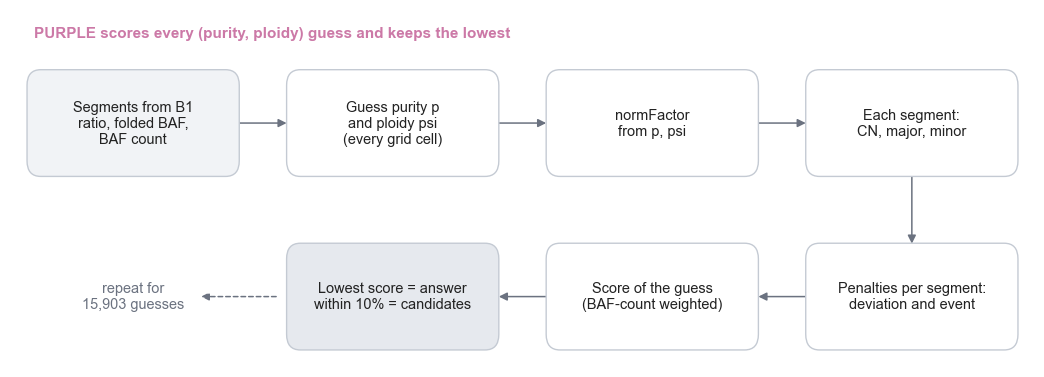

In [2]:
draw_concept_map()

## 1. 데이터

B1 에서 만든 것과 같은 가짜 종양을 purity 0.6, 깊이 60 으로 읽었다고 둡니다.
이 노트북은 **맞추기만** 보려고 구간 경계는 진짜 경계를 그대로 씁니다(SV 가 모든 끊김을 알려 줬다고 가정). 데이터에서 직접 구간을 나누면 무슨 일이 생기는지는 B3 에서 봅니다.

PURPLE 이 구간마다 쓰는 값은 세 개입니다 [1]: 깊이 비 중앙값(`observedTumorRatio`), 접힌 BAF 중앙값(`observedBAF`), BAF 점 수(`bafCount`).
BAF 점 수는 그 구간을 얼마나 믿을지의 무게로 쓰입니다.

In [3]:
TRUE_PURITY, DEPTH = 0.6, 60
prof = pm.random_profile(seed=1)
TRUE_PLOIDY = pm.profile_ploidy(prof)
bins, bafs = pm.simulate(prof, TRUE_PURITY, depth=DEPTH, seed=0)
segs = pm.summarize(bins, bafs, pm.true_segments(prof))
print(f"true purity {TRUE_PURITY}, true ploidy {TRUE_PLOIDY:.2f}, segments {len(segs)}")
segs[["chromosome", "start_bin", "end_bin", "observedTumorRatio", "observedBAF", "bafCount", "depthWindowCount", "true_cn"]].head()

true purity 0.6, true ploidy 2.22, segments 98


,chromosome,start_bin,end_bin,observedTumorRatio,observedBAF,bafCount,depthWindowCount,true_cn
0,1,0,686,0.953579,0.545455,20949,68600,2.0
1,1,686,1052,1.220241,0.616279,10926,36600,3.0
2,1,1052,2039,0.662519,0.717391,29525,98700,1.0
3,1,2039,2137,0.936179,0.543860,2944,9800,2.0
4,1,2137,2480,1.189598,0.615385,10100,34300,3.0


## 2. "맞춘다"는 것: 추측 하나를 넣으면 major·minor 가 정수에 떨어지는가

**한 줄 정의**: 맞추기는 (purity, ploidy) 를 하나 추측해 넣고, 그 추측으로 계산한 구간들의 major·minor 가 **정수에 얼마나 잘 떨어지는지** 보는 일입니다 [1].

**왜 정수인가**: 모든 종양 세포가 같은 CN 을 가진 클론 구간이라면 copy 수는 정수여야 합니다. 정수에서 벗어나려면 세포마다 CN 이 다른 subclone 이 있어야 하므로,
PURPLE 은 "정수에서 많이 벗어나는 추측"을 나쁜 추측으로 봅니다 [1].

**숫자로 따라가기** (구간 하나를 손으로 계산, 추측 = purity 0.6, ploidy 2.22)

1. normFactor: $n_f = 2\bar r/(2 - 2p + \psi p)$ (B1 4절).
2. CN: $2 + 2(r - n_f)/(p n_f)$.
3. 종양 BAF: 관찰 BAF 에서 정상 몫을 빼고 되돌립니다(B1 6절).
4. major = 종양 BAF × CN, minor = CN − major.

In [4]:
avg_ratio = np.average(segs.observedTumorRatio, weights=segs.bafCount)
p, psi = 0.6, 2.22
nf = pm.norm_factor(p, psi, avg_ratio)
ex = segs.iloc[[0, 1, 2]].copy()
ex["CN"] = pm.cn_from_ratio(ex.observedTumorRatio, p, nf)
ex["tumourBAF"] = pm.baf_from_observed(ex.observedBAF, p, ex.CN)
ex["major"] = ex.tumourBAF * ex.CN
ex["minor"] = ex.CN - ex.major
print(f"normFactor = {nf:.4f}")
ex[["observedTumorRatio", "observedBAF", "CN", "tumourBAF", "major", "minor", "true_cn"]].round(3)

normFactor = 0.9368


,observedTumorRatio,observedBAF,CN,tumourBAF,major,minor,true_cn
0,0.954,0.545,2.060,0.575,1.184,0.876,2.0
1,1.220,0.616,3.008,0.668,2.009,0.999,3.0
2,0.663,0.717,1.024,1.000,1.024,-0.000,1.0


첫 구간(진짜 1+1)만 major 1.18, minor 0.88 로 조금 어긋납니다. B1 6절에서 본 **접기 치우침** 때문입니다: 균형 구간도 접으면 관찰 BAF 가 0.5 가 아니라 0.54 근처로 올라갑니다(표의 `observedBAF`).
PURPLE 은 관찰 BAF 가 모호 판정 기준선(깊이 60 에서 0.556, B1 6절) 이하이면, BAF 를 0.5 로 볼 때와 관찰값으로 볼 때의 벌점을 비교해 작은 쪽을 씁니다(`RegionFitCalculator.bafToMinimiseDeviation` [2]).

`purple_mini` 가 원본과 다른 점 두 가지:
- 원본은 그 비교 전에 정수 해를 찾는 단계(`estimateMinMaxBaf`)가 하나 더 있는데, `purple_mini` 는 그 단계를 뺐습니다.
- 관찰값 쪽이 이기면 원본은 **보정 전 관찰 BAF** 를 그대로 종양 BAF 로 씁니다(`? BAF_PNT_5 : observedBAF` [2]). `purple_mini` 는 purity 로 보정한 값을 씁니다.

이제 추측 세 개를 나란히 놓고 구간 전체를 봅니다: 맞는 추측, purity 만 틀린 추측, ploidy 만 틀린 추측.

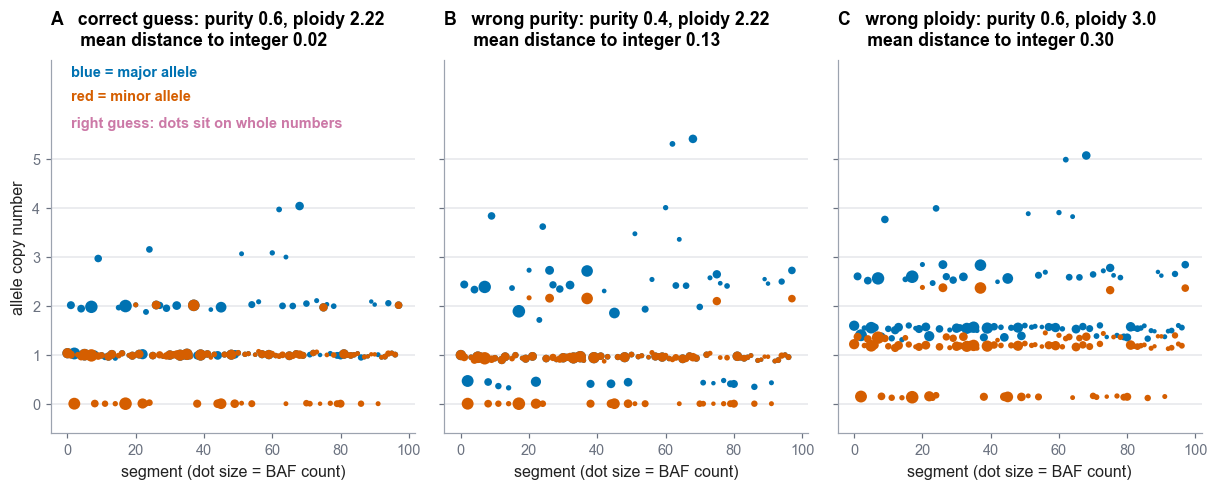

In [5]:
draw_three_guesses(segs, [("correct guess", 0.6, 2.22), ("wrong purity", 0.4, 2.22), ("wrong ploidy", 0.6, 3.0)])

**그림에서 볼 것**
- 왼쪽(맞는 추측): 파랑(major)과 빨강(minor) 점이 회색 정수선 위에 거의 다 올라앉습니다.
- 가운데(purity 만 틀림): 눈금 간격이 틀려 점들이 정수 사이로 흩어집니다. 정수와의 평균 거리가 커집니다.
- 오른쪽(ploidy 만 틀림): normFactor 가 바뀌어 0 점이 밀렸습니다. 점들이 한쪽으로 쏠려 정수에서 벗어납니다.
- 점 크기는 BAF 점 수입니다. 큰 점(긴 구간)이 점수에 더 크게 들어갑니다 [1].

**직접 바꿔 보기**: 세 번째 추측을 `("doubled", 0.43, 4.44)` 로 바꿔 보세요. 정수에 꽤 잘 떨어집니다. 이 노트북 7절의 "두 배 해"입니다.

## 3. 추측의 격자

**한 줄 정의**: PURPLE 은 purity 를 0.08~1.0 까지 0.01 간격으로, ploidy 를 1~8 까지(1~3 은 0.02, 3~5 는 0.05, 5 이상은 0.1 간격) 바꿔 가며 모든 조합을 시험합니다 [1][2].

**왜 필요한가**: purity 와 ploidy 는 서로 얽혀 있어(7절) 하나씩 따로 찾을 수 없습니다. 그래서 둘을 함께 훑습니다.
조합마다 normFactor 가 하나로 정해지므로, 격자는 "purity × normFactor" 를 훑는 것과 같습니다.

**숫자로 따라가기**: purity 93 개 × ploidy 171 개 = 15,903 개 추측입니다. 추측 하나마다 구간 수백 개를 계산합니다.

설명서 본문은 "purity 7%~100%, 1% 간격, 20% 아래에서는 0.5% 간격"이라고 적지만, 같은 설명서의 설정 표는 최솟값을 0.08 로 적습니다 [1].
4.1 코드는 최솟값 0.08(`PurpleConstants`)과 고정 간격 0.01(`FittedPurityFactory`)을 씁니다 [2]. 이 노트북은 코드를 따릅니다.

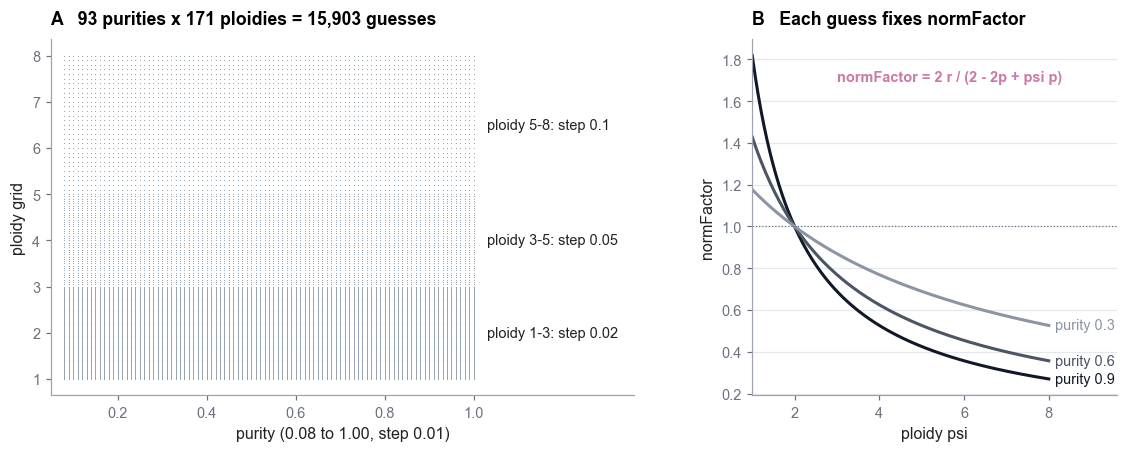

In [6]:
draw_grid()
assert len(pm.purity_grid()) == 93 and len(pm.ploidy_grid()) == 171

**그림에서 볼 것**
- 왼쪽: 점 하나가 추측 하나입니다. ploidy 3 과 5 에서 간격이 넓어집니다.
- 오른쪽: 같은 purity 에서 ploidy 를 올리면 normFactor 가 내려갑니다. B1 4절 그림 B 의 "0 점이 밀리는 것"입니다. purity 가 높을수록 더 크게 움직입니다.

## 4. deviation 벌점: 정수에서 얼마나 벗어났나

**한 줄 정의**: major·minor 가 가장 가까운 정수에서 떨어진 거리를, purity 에 맞춘 "표준편차 몇 개"로 바꿔 0~1 사이 벌점으로 만든 것입니다 (`PloidyDeviation.java` [2]).

**왜 purity 를 고려하나**: purity 가 낮으면 copy 하나가 만드는 깊이 비 차이(B1 의 $n_f p/2$)가 작아, 같은 잡음에도 계산된 CN 이 더 흔들립니다.
그래서 PURPLE 은 **purity 가 낮을수록 같은 거리에 벌점을 덜 줍니다** [1]. 설명서는 이것을 "낮은 purity 에서는 예상 잡음이 크므로 벌점을 천천히 올린다"고 적습니다.

**식과 근거** [2]
1. 가장 가까운 정수까지 거리 $d$ (0~0.5).
2. copy 하나 = 표준편차 $k = \max(1.5,\; p \cdot n_f / 2 / 0.05)$ 개. 0.05 는 코드에서 `PLOIDY_PENALTY_STANDARD_DEVIATION` 이라는 상수입니다. 설명서에 정의는 없지만, 식의 단위로 보면 깊이 비의 표준편차로 해석됩니다($p n_f/2$ 가 copy 하나당 깊이 비이므로).
3. 벌점 = $2\Phi(d \cdot k) - 1$ ($\Phi$: 표준정규 누적분포). 거리 0 이면 0, 멀어질수록 1 에 가까워집니다.
4. 바닥값 0.1 을 깔고(설명서는 0.2 라고 적지만 4.1 WGS 코드 기본값은 0.1 이고 0.2 는 targeted 값입니다 [1][2]), major < 1 이거나 minor < 0 이면 추가 벌점을 더합니다.

**숫자로 따라가기** ($n_f = 1$, 거리 $d = 0.2$)

| purity | copy 하나 = SD 몇 개 | 0.2 copy = SD 몇 개 | 벌점 $2\Phi - 1$ |
|---|---|---|---|
| 0.7 | 0.7/2/0.05 = 7 | 1.4 | 0.84 |
| 0.3 | 0.3/2/0.05 = 3 | 0.6 | 0.45 |

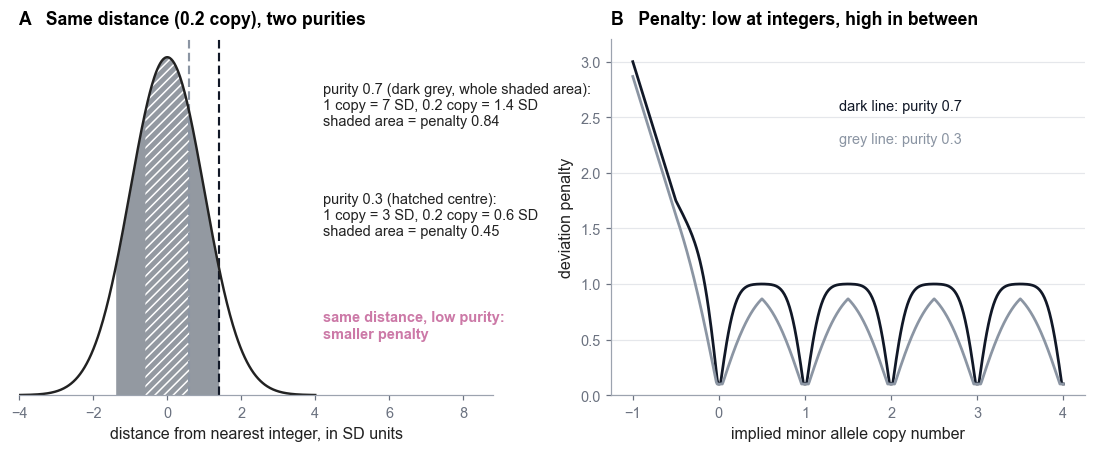

In [7]:
draw_deviation_concept(d=0.2)
assert np.isclose(2 * norm.cdf(1.4) - 1, 0.84, atol=0.005) and np.isclose(2 * norm.cdf(0.6) - 1, 0.45, atol=0.005)

**그림에서 볼 것**
- 왼쪽: 같은 0.2 copy 거리가 purity 0.7 에서는 SD 1.4 개(진한 회색으로 칠한 넓이 전체, 0.84), purity 0.3 에서는 SD 0.6 개(가운데 빗금 친 넓이, 0.45)입니다. 오른쪽 그림에서도 purity 0.7 은 진한 선, 0.3 은 옅은 선입니다. 칠한 넓이가 벌점입니다.
- 오른쪽: 벌점 곡선. 정수(0, 1, 2, 3)에서 바닥이고 정수 사이에서 올라갑니다. purity 0.3 곡선이 더 완만합니다. 0 아래(음수 copy, 불가능)는 가파르게 커집니다.

아래에서 직접 짠 함수가 `purple_mini` 와 같은지 확인합니다.

In [8]:
def my_allele_deviation(purity, nf, acn):
    d = np.where(acn < -0.5, 0.5, np.abs(acn - np.round(acn)))       # 가장 가까운 정수까지 거리
    sd_per_copy = np.maximum(1.5, purity * nf / 2 / 0.05)            # copy 하나 = 표준편차 몇 개
    return 2 * norm.cdf(d * sd_per_copy) - 1 + np.maximum(-0.5 - acn, 0)

def my_minor_deviation(purity, nf, acn):
    extra = np.minimum(1.5, np.maximum(0, -1.5 * (acn - 0)))          # minor < 0 이면 추가 벌점
    return np.maximum(my_allele_deviation(purity, nf, acn) + extra, 0.1)

acn = np.linspace(-1, 4, 501)
for p in [0.3, 0.7]:
    assert np.allclose(my_minor_deviation(p, 1.0, acn), pm.minor_allele_deviation(p, 1.0, acn))
print("my_minor_deviation == purple_mini.minor_allele_deviation")

my_minor_deviation == purple_mini.minor_allele_deviation


구간의 deviation 벌점은 $(\text{minor 벌점} + \text{major 벌점}) \times \text{관찰 BAF}$ 입니다 [1].
BAF 가 높은 구간은 가능한 해가 적어 더 믿을 만하므로 무게를 더 줍니다.

**직접 바꿔 보기**: `draw_deviation_concept(d=0.35)` 로 거리를 키워 보세요. purity 0.7 에서는 벌점이 거의 1 이 됩니다.

## 5. event 벌점: 정상에서 얼마나 멀리 왔나

**한 줄 정의**: 정상(major 1, minor 1)에서 그 구간 상태까지 가려면 사건(copy 얻기·잃기)이 몇 번 필요한지에 매기는 벌점입니다 (`RegionFitCalculator.calculateEventPenalty` [2]).

**왜 필요한가**: deviation 벌점만 쓰면 ploidy 를 높일수록 정수 간격이 촘촘해져 아무 데이터나 정수로 맞출 수 있습니다.
설명서는 이 벌점이 "벌점은 낮지만 그럴듯하지 않은 높은 ploidy 해를 누르기 위한 것"이라고 적습니다 [1].

**식과 근거**

$$\text{event} = 1 + 0.4 \times \min\big(|M-1| + |m-1|,\; 1 + |M-2| + |m-2|\big)$$

두 번째 항은 유전체 전체가 한 번에 두 배가 되는 사건(WGD)을 한 번으로 쳐 주는 할인입니다 [1]. 설명서에는 계수 0.3 으로 적혀 있지만 4.1 코드 기본값은 0.4 입니다 [1][2].

**숫자로 따라가기**

| 상태 | 정상에서 하나씩 | WGD 거쳐서 | 작은 쪽 | 벌점 |
|---|---|---|---|---|
| (2,1) | 1 | 1 + 0 + 1 = 2 | 1 | 1.4 |
| (2,2) | 2 | 1 + 0 + 0 = 1 | 1 | 1.4 |
| (4,4) | 6 | 1 + 2 + 2 = 5 | 5 | 3.0 |

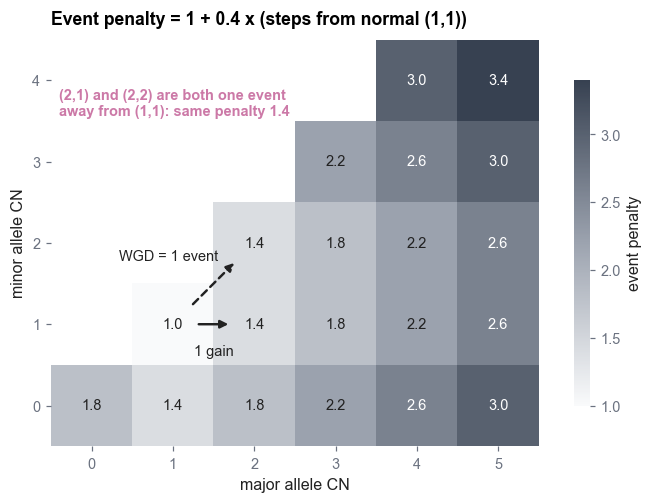

In [9]:
draw_event_heatmap()

**그림에서 볼 것**
- 칸의 숫자가 event 벌점입니다. 정상 (1,1) 만 1.0 이고 멀어질수록 커집니다.
- 검은 실선 화살표(gain 한 번)와 검은 점선 화살표(WGD 한 번)는 둘 다 사건 하나라 (2,1) 과 (2,2) 가 같은 1.4 입니다.
- (4,2), (4,4) 같은 높은 상태는 진하게 칠해집니다. 높은 ploidy 해는 이 벌점을 많이 받습니다.

In [10]:
rows = [(1, 1), (1, 0), (2, 1), (2, 0), (2, 2), (3, 1), (4, 2), (4, 4)]
tab = pd.DataFrame(rows, columns=["major", "minor"])
tab["event_penalty"] = pm.event_penalty(tab.major, tab.minor)
assert np.isclose(pm.event_penalty(2, 2), 1.4) and np.isclose(pm.event_penalty(1, 1), 1.0) and np.isclose(pm.event_penalty(4, 4), 3.0)
tab

,major,minor,event_penalty
0,1,1,1.0
1,1,0,1.4
2,2,1,1.4
3,2,0,1.8
4,2,2,1.4
5,3,1,1.8
6,4,2,2.2
7,4,4,3.0


## 6. 점수를 모으고 답 고르기

**한 줄 정의**: 추측 하나의 점수 = (구간 event 벌점의 BAF 가중 평균) × (구간 deviation 벌점의 BAF 가중 평균) 입니다 [1].
정상 시료에서 이배체이고 깊이 비가 평균의 3 배 미만인 구간만 씁니다 [1]. 점수가 가장 낮은 추측이 답입니다.

**숫자로 따라가기** (구간 세 개짜리 장난감)

| 구간 | BAF 점 수 | event | deviation |
|---|---|---|---|
| A | 600 | 1.0 | 0.12 |
| B | 300 | 1.4 | 0.20 |
| C | 100 | 1.4 | 0.60 |

event 평균 = (600×1.0 + 300×1.4 + 100×1.4)/1000 = 1.16, deviation 평균 = (600×0.12 + 300×0.20 + 100×0.60)/1000 = 0.192, 점수 = 1.16 × 0.192 ≈ 0.223.

실제 PURPLE 은 체세포 SNV 벌점도 더합니다(`점수 = deviation × event + somatic` [1]). 이 노트북은 그 항을 뺐고, SNV 는 B3 에서 따로 다룹니다.
PURPLE 출력의 `ploidy` 는 격자의 $\psi$ 가 아니라 그 추측으로 계산한 구간 CN 을 BAF 점 수로 가중 평균한 값입니다(`FittedPurityFactory.java` 의 `averagePloidy` [2]).

In [11]:
w = np.array([600, 300, 100]); ev = np.array([1.0, 1.4, 1.4]); dv = np.array([0.12, 0.20, 0.60])
toy_score = np.average(ev, weights=w) * np.average(dv, weights=w)
assert np.isclose(toy_score, 1.16 * 0.192)

fits = pm.fit(segs, DEPTH)
s = pm.summary(fits)
print(f"best: purity {s['purity']:.2f}, ploidy {s['ploidy']:.2f}, score {s['score']:.4f}")
print(f"candidate range: purity {s['minPurity']:.2f} - {s['maxPurity']:.2f}, ploidy {s['minPloidy']:.2f} - {s['maxPloidy']:.2f}")
assert abs(s["purity"] - TRUE_PURITY) <= 0.02
assert abs(s["ploidy"] - TRUE_PLOIDY) <= 0.1
fits.head()

best: purity 0.61, ploidy 2.24, score 0.1841
candidate range: purity 0.59 - 0.62, ploidy 2.20 - 2.26


,purity,ploidyGrid,normFactor,score,diploidProportion,ploidy,eventPenalty,deviationPenalty
0,0.61,2.24,0.930532,0.184133,0.497232,2.24,1.272056,0.144752
1,0.60,2.22,0.936817,0.184276,0.497232,2.22,1.271970,0.144875
2,0.60,2.24,0.931574,0.184925,0.497232,2.24,1.275378,0.144997
3,0.61,2.22,0.935852,0.187316,0.497232,2.22,1.269116,0.147596
4,0.59,2.22,0.937785,0.193602,0.497232,2.22,1.274525,0.151901


진짜 purity 0.6, ploidy 2.22 를 거의 그대로 찾았습니다. 이제 1 만 6 천 개 추측의 점수를 한 장에 그려 봅니다(**점수 지형**).
색이 어두울수록 점수가 낮습니다(좋습니다). 점수 차이가 커서 로그 눈금으로 칠했습니다.

grid cells: 15903


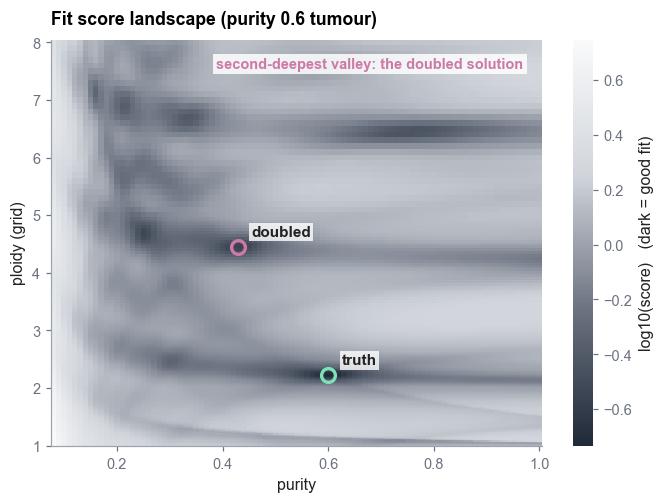

In [12]:
print("grid cells:", len(fits))
dbl_p = TRUE_PURITY / (2 - TRUE_PURITY)
draw_landscape(fits, TRUE_PURITY, TRUE_PLOIDY)

**그림에서 볼 것**: 진짜 해(초록 원) 말고도 골짜기가 여러 개 있습니다(높은 ploidy 쪽에 몇 개 더). 그중 **가장 깊은 두 번째 골짜기**가 자주색 원으로 표시한 **"두 배 해"** 근처입니다(최저 점수의 약 1.46 배, 이 노트북의 시뮬레이션 결과). 7절에서 이유를 봅니다.

### 후보 범위

**한 줄 정의**: 가장 낮은 점수에서 10% 또는 0.0005 안에 드는 추측들입니다. PURPLE 은 그 purity·ploidy 의 최솟값·최댓값을 `minPurity`~`maxPurity`, `minPloidy`~`maxPloidy` 로 적어 답의 불확실성을 보여 줍니다 (`PurityPloidyFitter.java` [1][2]).

**왜 필요한가**: 점수가 거의 같은 추측이 넓게 퍼져 있으면 답을 믿기 어렵습니다. 이 범위가 넓은 시료는 B3·B4 에서 다시 봅니다.

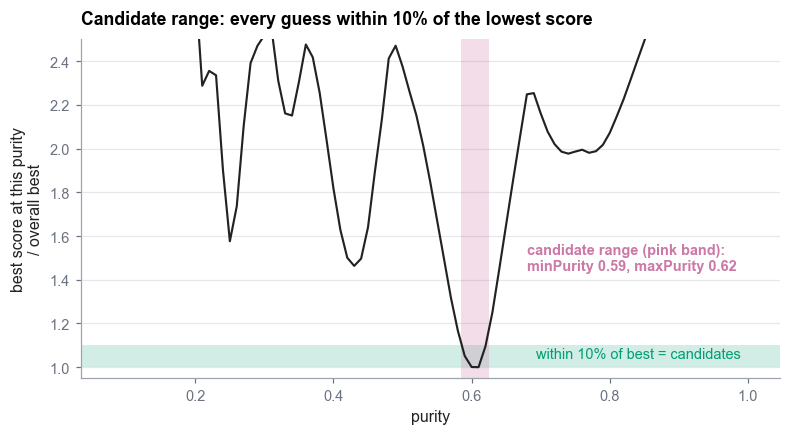

In [13]:
draw_candidates(fits)

**그림에서 볼 것**: 검은 선은 purity 마다 가장 좋은 점수를 전체 최저 점수로 나눈 것입니다. 초록 띠(1.0~1.1) 안에 드는 purity 가 후보이고, 분홍 세로 띠가 그 범위입니다.
깨끗한 데이터라 골짜기가 뾰족하고 범위가 좁습니다. purity 0.25, 0.43, 0.74 근처에도 골짜기가 있지만 모두 10% 선 위라 후보가 아닙니다. **10% 선 아래 골짜기는 하나**입니다.

## 7. 똑같이 잘 맞는 다른 해: purity $p/(2-p)$, CN 두 배

**한 줄 정의**: 모든 구간의 CN 을 두 배로 하고(major·minor 도 두 배) purity 를 $p' = p/(2-p)$ 로 낮추면, **깊이 비와 BAF 가 하나도 바뀌지 않습니다.**

**왜 중요한가**: 데이터만으로는 두 설명을 가를 수 없습니다. ABSOLUTE 논문도 "한 시료에서 이론적으로 가능한 여러 purity·ploidy·CN 조합이 같은 copy ratio 를 만들 수 있다"고 적고,
특히 WGD 뒤에 추가 변화가 없으면 진짜 ploidy 의 절반인 해가 나올 수 있다고 적습니다 [3].

**숫자로 따라가기** (purity 0.5, 같은 길이 구간 세 개)

| | 설명 1: purity 0.50 | 설명 2: purity 0.33 |
|---|---|---|
| 구간 상태 | (1,1), (2,1), (1,0) | (2,2), (4,2), (2,0) |
| DNA 양 = p·CN + 2(1−p) | 2.0, 2.5, 1.5 (평균 2.0) | 2.67, 3.33, 2.00 (평균 2.67) |
| 깊이 비 = DNA ÷ 평균 | 1.00, 1.25, 0.75 | 1.00, 1.25, 0.75 |
| BAF (major) | 0.50, 0.60, 0.67 | 0.50, 0.60, 0.67 |

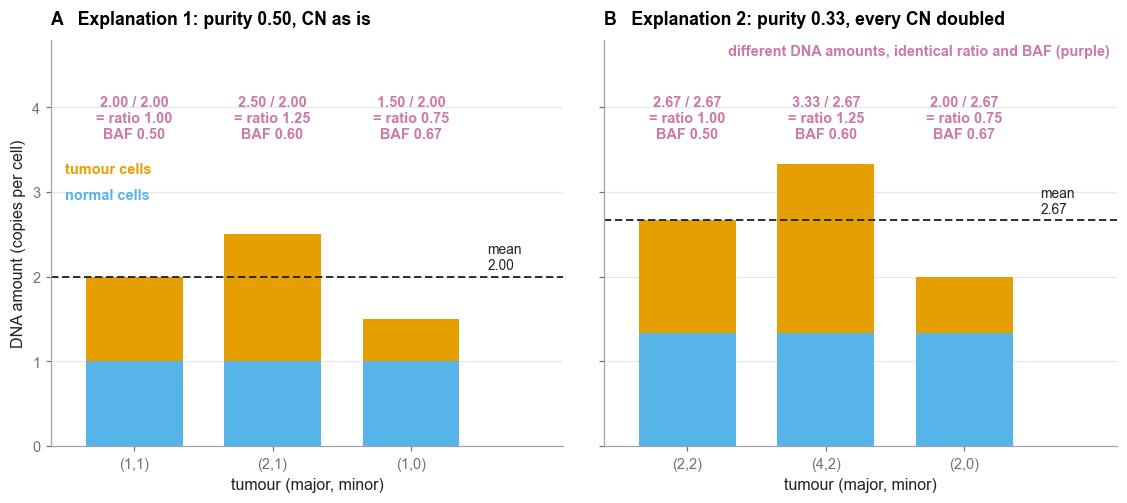

In [14]:
draw_doubled(p=0.5)

**그림에서 볼 것**
- 막대(실제 DNA 양)는 왼쪽과 오른쪽이 다릅니다. 오른쪽은 종양 세포가 적고(33%) 대신 종양 세포 하나가 copy 를 두 배로 가집니다. 정상 몫(하늘색)도 1.00 대 1.33 으로 다릅니다.
- 그런데 각 막대를 그 그림의 평균(점선)으로 나눈 **깊이 비**와 **BAF** 는 숫자가 정확히 같습니다.
- 시퀀싱으로 보는 것은 이 상대값뿐입니다(B1 4절: COBALT 는 깊이를 시료 전체 수준으로 나눕니다). 그래서 데이터로는 두 설명을 가를 수 없습니다.

**식으로 쓰면**: 깊이 비는 $n_f' p' = n_f p/2$, $n_f'(1-p') = n_f(1-p)$ 가 되도록 $n_f'$ 를 잡으면 $n_f'(1 - p' + p' \cdot 2CN/2) = r$ 입니다.
BAF 는 분자와 분모를 $(1-p')$ 로 나누면 $p'/(1-p') = p/(2(1-p))$ 이므로 원래 식과 같아집니다. 숫자로 확인합니다.

In [15]:
p = 0.5
p2 = p / (2 - p)
for M, m in [(1, 1), (1, 0), (2, 1), (3, 0), (2, 2)]:
    cn = M + m
    r1 = pm.relative_dna(p, cn) / pm.relative_dna(p, 2.1)
    r2 = pm.relative_dna(p2, 2 * cn) / pm.relative_dna(p2, 4.2)
    b1, b2 = pm.expected_baf(p, M, m), pm.expected_baf(p2, 2 * M, 2 * m)
    assert np.isclose(r1, r2) and np.isclose(b1, b2)
    print(f"({M},{m}) at purity {p}: ratio {r1:.4f}, BAF {b1:.4f}  |  ({2 * M},{2 * m}) at purity {p2:.3f}: ratio {r2:.4f}, BAF {b2:.4f}")

(1,1) at purity 0.5: ratio 0.9756, BAF 0.5000  |  (2,2) at purity 0.333: ratio 0.9756, BAF 0.5000
(1,0) at purity 0.5: ratio 0.7317, BAF 0.6667  |  (2,0) at purity 0.333: ratio 0.7317, BAF 0.6667
(2,1) at purity 0.5: ratio 1.2195, BAF 0.6000  |  (4,2) at purity 0.333: ratio 1.2195, BAF 0.6000
(3,0) at purity 0.5: ratio 1.2195, BAF 0.8000  |  (6,0) at purity 0.333: ratio 1.2195, BAF 0.8000
(2,2) at purity 0.5: ratio 1.4634, BAF 0.5000  |  (4,4) at purity 0.333: ratio 1.4634, BAF 0.5000


데이터가 같으니 deviation 벌점도 비슷합니다. **둘을 가르는 것은 event 벌점**입니다. 두 배 해에서는 정상 구간 (1,1) 이 (2,2) 가 되어 event 벌점이 1.0 에서 1.4 로 오릅니다.

In [16]:
def nearest(fits, purity, ploidy):
    return fits.iloc[((fits.purity - purity).abs() * 10 + (fits.ploidyGrid - ploidy).abs()).argsort().iloc[0]]

cmp = pd.DataFrame([nearest(fits, TRUE_PURITY, TRUE_PLOIDY), nearest(fits, dbl_p, 2 * TRUE_PLOIDY)],
                   index=["truth", "doubled"])[["purity", "ploidy", "eventPenalty", "deviationPenalty", "score"]]
cmp.round(3)

,purity,ploidy,eventPenalty,deviationPenalty,score
truth,0.60,2.22,1.272,0.145,0.184
doubled,0.43,4.45,1.899,0.142,0.269


두 배 해의 deviation 벌점은 진짜 해와 비슷하거나 오히려 낮습니다. purity 가 낮으면 벌점을 봐주기 때문입니다(4절).
event 벌점이 더 높아서 총점에서 집니다.

점수는 **곱**(event × deviation)이므로 비율로 따져야 합니다. 이 표에서 두 배 해의 event 벌점은 진짜 해의 1.899 ÷ 1.272 ≈ **1.49 배**입니다.
진짜 해의 deviation 벌점이 두 배 해의 1.49 배를 넘으면 답이 뒤집힙니다. 지금은 0.145 ÷ 0.142 ≈ 1.02 배라 진짜 해가 이깁니다(이 노트북의 시뮬레이션 결과).
잡음이 커져 진짜 해의 deviation 벌점이 올라가면 이 균형이 뒤집힐 수 있습니다. 그것이 B3 의 핵심입니다.

## 8. 맞춘 CN 이 진짜와 같은가

최적해로 구간마다 CN 과 major·minor 를 다시 계산해 진짜와 비교합니다.

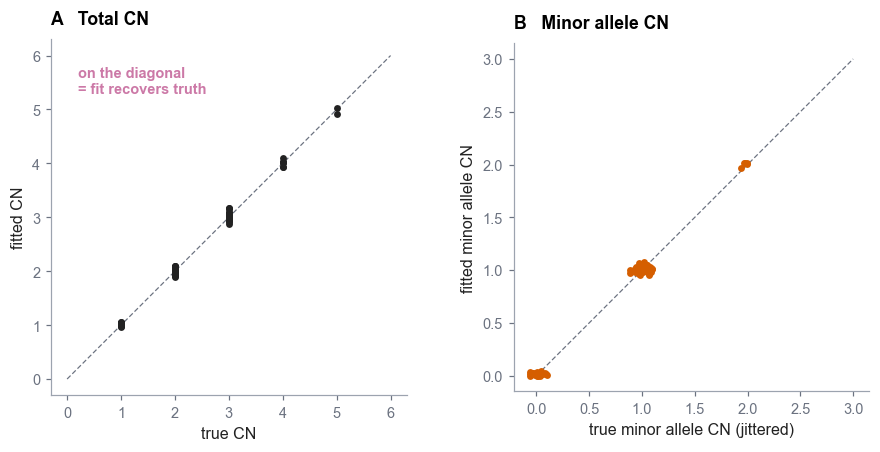

median |fitted CN - true CN| = 0.034


In [17]:
fitted = pm.apply_fit(segs, s["purity"], s["normFactor"], DEPTH)
true_minor = prof.minor.to_numpy()
draw_fitted_vs_true(fitted, true_minor)
err = (fitted.tumorCopyNumber - fitted.true_cn).abs()
print(f"median |fitted CN - true CN| = {err.median():.3f}")
assert err.median() < 0.15

**그림에서 볼 것**: 점이 대각선(점선)에 붙어 있으면 맞춘 CN 이 진짜와 같습니다. 왼쪽(총 CN)은 거의 대각선 위이고, 오른쪽(minor)은 minor 0 과 1 이 잘 갈립니다.

## 연습 문제

1. purity 0.4 종양의 "두 배 해" purity 는 얼마입니까?
2. major 3, minor 0 구간의 event 벌점은 얼마입니까?
3. purity 0.2, $n_f = 1$ 일 때 copy 하나는 표준편차 몇 개에 해당합니까? purity 0.8 이면?
4. 6절 코드에서 `pm.PLOIDY_PENALTY_FACTOR` 를 0 으로 바꾸면 무엇이 달라질 것 같습니까? 바꿔서 돌려 보고, 끝나면 0.4 로 되돌리세요.

<details><summary>정답 보기</summary>

1. $0.4 / 1.6 = 0.25$.
2. $\min(|3-1| + |0-1|,\; 1 + |3-2| + |0-2|) = \min(3, 4) = 3$, 벌점 $1 + 0.4 \times 3 = 2.2$.
3. purity 0.2: $0.2/2/0.05 = 2$ 개. purity 0.8: 8 개. 낮은 purity 에서는 copy 하나가 잡음 두 개 크기밖에 안 되어 벌점이 완만합니다.
4. event 벌점이 사라지면 deviation 벌점만 남습니다. deviation 벌점은 낮은 purity·높은 ploidy 해에 너그러우므로 두 배 해가 이깁니다. 이 데이터로 돌리면 purity 0.43 ($= 0.6/1.4$), ploidy 4.45 가 답이 되고, 후보 범위가 purity 0.21~0.80 으로 넓어집니다(이 노트북의 시뮬레이션 결과).

</details>

In [18]:
assert np.isclose(0.4 / (2 - 0.4), 0.25)
assert np.isclose(pm.event_penalty(3, 0), 2.2)

## 정리

- PURPLE 은 purity × ploidy 격자의 모든 추측을 시험하고, 추측마다 **(event 벌점 평균) × (deviation 벌점 평균)** 이 가장 작은 것을 고릅니다.
- deviation 벌점은 major·minor 가 정수에서 벗어난 정도입니다. copy 하나를 표준편차 $p n_f/2/0.05$ 개로 보므로, **purity 가 낮은 해일수록 벌점이 너그럽습니다.**
- event 벌점은 정상에서 얼마나 많은 사건을 거쳤는지입니다. 높은 ploidy 해를 누르는 장치입니다.
- purity $p/(2-p)$ 에 CN 을 모두 두 배로 한 해는 깊이 비와 BAF 를 **똑같이** 설명합니다. 깨끗한 데이터에서는 event 벌점 덕에 진짜 해가 이깁니다.

다음 노트북(B3)에서는 purity 를 낮추고 잡음을 늘려, 이 균형이 어떻게 무너지는지 봅니다.

## 출처

모두 2026-11-13 에 직접 열어 확인했습니다.

1. **PURPLE README**, hmftools 태그 `purple-v4.1`. https://github.com/hartwigmedical/hmftools/blob/purple-v4.1/purple/README.md
   — 이 노트북에서: 모든 purity·ploidy 조합을 점수로 매기는 방식과 다섯 원칙(Algorithm 3), deviation 벌점의 정의와 "낮은 purity 에서 천천히 올림", 관찰 BAF 가중, event 벌점 식(계수 0.3 표기)과 WGD 할인, 점수 식(deviation × event + somatic), 이배체·깊이 비 3 배 미만 구간만 쓰는 규칙, 후보(10% 또는 0.0005), 격자 범위와 ploidy 간격 표, purity 0.005 간격 문장.
2. **PURPLE 소스**, 태그 `purple-v4.1`. https://github.com/hartwigmedical/hmftools/tree/purple-v4.1/purple/src/main/java/com/hartwig/hmftools/purple
   — `PurpleConstants.java`(event 계수 0.4, `PLOIDY_PENALTY_STANDARD_DEVIATION` 0.05, 최소 SD 1.5, 바닥 0.1·targeted 0.2, purity 0.08~1.0·0.01), `fitting/FittedPurityFactory.java`(격자, ploidy 간격, 출력 ploidy = BAF 점 수 가중 평균 CN), `region/PloidyDeviation.java`(벌점 식), `fitting/RegionFitCalculator.java`(event 벌점, `bafToMinimiseDeviation`, `estimateMinMaxBaf`), `fitting/PurityAdjuster.java`, `fitting/PurityPloidyFitter.java`(후보 0.1·0.0005).
3. **Carter SL, et al.** (2012) Absolute quantification of somatic DNA alterations in human cancer. *Nat Biotechnol* 30:413–421. https://doi.org/10.1038/nbt.2203
   — 여러 purity·ploidy·CN 조합이 같은 copy ratio 를 만들 수 있음(Online Methods "Karyotype models"), WGD 뒤 변화가 없으면 진짜 ploidy 의 절반인 해가 나올 수 있음(Online Methods "Limitations of joint purity/ploidy inference").
4. **Van Loo P, et al.** (2010) Allele-specific copy number analysis of tumors. *PNAS* 107:16910–16915. https://doi.org/10.1073/pnas.1009843107
   — purity 와 ploidy 를 함께 추정하는 같은 계열의 방법(ASCAT). PURPLE 은 개발 때 ASCAT 결과와 비교 검증되었습니다 [5].
5. **Priestley P, et al.** (2019) Pan-cancer whole-genome analyses of metastatic solid tumours. *Nature* 575:210–216. https://doi.org/10.1038/s41586-019-1689-y
   — PURPLE 의 검증(시뮬레이션 purity, FISH, ASCAT 비교) 설명(Methods).

2절·6절·7절의 장난감 표와 4절 연습 문제 4 의 수치는 **이 노트북의 시뮬레이션 결과**입니다.